# 9주차 과제 | 자연어 처리(NLP)
### KUGGLE 14기 정기세션
**주제: 텍스트 전처리 → BoW·TF-IDF → 감정 분류**

4주차 과제와 동일하게 설명을 읽고 코드의 `_____`를 완성하세요. **빈칸은 총 12개**입니다. 순서대로 실행하며 결과를 확인하세요.

- 실행 환경: VS Code(Jupyter 확장) 또는 Google Colab
- 라이브러리: pandas, scikit-learn, matplotlib (별도 데이터 다운로드 불필요)
- 제출: 완성한 `.ipynb` 파일과 마지막 해석 문항 답변
- 주의: 테스트 데이터는 학습에 사용하지 않습니다.

## Part 1. 전처리와 토큰화
텍스트는 모델이 바로 계산할 수 없으므로 먼저 정리하고 토큰 단위로 분리합니다. 아래는 학습을 위한 간단한 **공백 기준 토큰화** 예시입니다. 실제 한국어 NLP에서는 형태소/서브워드 토크나이저를 사용하기도 합니다.

In [1]:
import re
import pandas as pd
import numpy as np

reviews = [
    "배송이 정말 빨라요!", "제품 품질이 좋고 만족해요", "가격도 좋고 배송도 빨라요",
    "정말 만족하고 추천합니다", "디자인이 예쁘고 사용하기 편해요", "배송 빠르고 품질도 훌륭해요",
    "좋은 제품이라 다시 구매할게요", "가격 대비 성능이 만족스러워요",
    "배송이 너무 늦어요", "제품 품질이 나쁘고 실망했어요", "가격이 비싸고 배송도 느려요",
    "정말 실망해서 추천하지 않아요", "디자인이 별로고 사용하기 불편해요",
    "배송 느리고 품질도 형편없어요", "나쁜 제품이라 다시 구매하지 않을게요",
    "가격 대비 성능이 실망스러워요", "배송이 빨라서 기분이 좋아요",
    "품질이 좋아서 매우 만족해요", "배송이 늦어서 기분이 나빠요",
    "품질이 나빠서 매우 실망했어요"
]
labels = [1]*8 + [0]*8 + [1,1,0,0]  # 1: 긍정, 0: 부정

df = pd.DataFrame({'review': reviews, 'label': labels})
print(df.head())
print('전체 데이터:', len(df), '/ 긍정:', sum(df.label), '/ 부정:', len(df)-sum(df.label))

              review  label
0        배송이 정말 빨라요!      1
1     제품 품질이 좋고 만족해요      1
2     가격도 좋고 배송도 빨라요      1
3      정말 만족하고 추천합니다      1
4  디자인이 예쁘고 사용하기 편해요      1
전체 데이터: 20 / 긍정: 10 / 부정: 10


#### [문제 1] 정규표현식으로 텍스트 정제하기
특수기호를 제거하고 공백을 정리합니다. **주의:** 실제 감정 분석에서는 느낌표·이모티콘도 중요한 단서일 수 있습니다.

In [2]:
def clean_text(text):
    # [빈칸 1] 한글, 영문, 숫자, 공백 이외의 문자를 공백으로 바꾸는 함수
    text = re.sub(r'[^가-힣a-zA-Z0-9\s]', ' ', text)
    # [빈칸 2] 여러 공백을 하나로 합치고 앞뒤 공백 제거
    text = ' '.join(text.split())
    return text

df['cleaned'] = df['review'].apply(clean_text)
print(df[['review','cleaned']].head())

              review            cleaned
0        배송이 정말 빨라요!         배송이 정말 빨라요
1     제품 품질이 좋고 만족해요     제품 품질이 좋고 만족해요
2     가격도 좋고 배송도 빨라요     가격도 좋고 배송도 빨라요
3      정말 만족하고 추천합니다      정말 만족하고 추천합니다
4  디자인이 예쁘고 사용하기 편해요  디자인이 예쁘고 사용하기 편해요


#### [문제 2] 간단한 토큰화
아래 코드는 공백을 기준으로 분리합니다. 조사·어미를 분리하는 형태소 분석과는 다릅니다.

In [3]:
# [빈칸 3] 문자열을 공백 기준으로 분리하는 메서드
df['tokens'] = df['cleaned'].apply(lambda x: x.split())
print(df[['cleaned','tokens']].head())

             cleaned                  tokens
0         배송이 정말 빨라요          [배송이, 정말, 빨라요]
1     제품 품질이 좋고 만족해요     [제품, 품질이, 좋고, 만족해요]
2     가격도 좋고 배송도 빨라요     [가격도, 좋고, 배송도, 빨라요]
3      정말 만족하고 추천합니다       [정말, 만족하고, 추천합니다]
4  디자인이 예쁘고 사용하기 편해요  [디자인이, 예쁘고, 사용하기, 편해요]


## Part 2. BoW·TF-IDF와 코사인 유사도
BoW는 단어의 등장 횟수를, TF-IDF는 문서 내 빈도와 전체 문서에서의 희귀도를 반영합니다. 문장 유사도는 코사인 유사도로 비교할 수 있습니다.

#### [문제 3] BoW 행렬 만들기

In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sample_docs = ['고양이 고양이 귀엽다', '강아지 귀엽다', '고양이 강아지 친구']
# [빈칸 4] 단어별 빈도를 세는 벡터화 클래스
bow = CountVectorizer(token_pattern=r'(?u)\b\w+\b')
X_bow = bow.fit_transform(sample_docs)
print('단어 목록:', bow.get_feature_names_out())
print(pd.DataFrame(X_bow.toarray(), columns=bow.get_feature_names_out()))

단어 목록: ['강아지' '고양이' '귀엽다' '친구']
   강아지  고양이  귀엽다  친구
0    0    2    1   0
1    1    0    1   0
2    1    1    0   1


#### [문제 4] TF-IDF 행렬 만들기

In [5]:
# [빈칸 5] TF-IDF 벡터화 클래스
tfidf = TfidfVectorizer(token_pattern=r'(?u)\b\w+\b')
# [빈칸 6] 어휘를 학습하고 문서를 벡터로 변환하는 메서드
X_tfidf = tfidf.fit_transform(sample_docs)
print(pd.DataFrame(np.round(X_tfidf.toarray(), 3), columns=tfidf.get_feature_names_out()))

     강아지    고양이    귀엽다     친구
0  0.000  0.894  0.447  0.000
1  0.707  0.000  0.707  0.000
2  0.518  0.518  0.000  0.681


#### [문제 5] 문장 간 코사인 유사도 비교
유사도가 1에 가까울수록 두 벡터의 방향이 비슷합니다. 같은 단어를 공유한다고 반드시 의미가 같은 것은 아닙니다.

In [6]:
# [빈칸 7] 두 문서 벡터 사이 코사인 유사도 계산 함수
sim = cosine_similarity(X_tfidf)
print(pd.DataFrame(np.round(sim, 3), index=['문서1','문서2','문서3'], columns=['문서1','문서2','문서3']))

       문서1    문서2    문서3
문서1  1.000  0.316  0.463
문서2  0.316  1.000  0.366
문서3  0.463  0.366  1.000


## Part 3. TF-IDF 기반 감정 분류
전처리된 리뷰를 TF-IDF로 수치화하고 로지스틱 회귀로 긍정/부정을 예측합니다. **데이터 누수 방지:** 벡터화기는 학습 데이터에만 `fit`합니다. 예제 데이터가 작아 성능 수치는 안정적인 일반화 성능을 의미하지 않습니다.

#### [문제 6] 학습/테스트 데이터 분리

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# [빈칸 8] 학습/테스트 분리 함수 (클래스 비율 유지)
X_train, X_test, y_train, y_test = train_test_split(
    df['cleaned'], df['label'], test_size=0.3, random_state=42, stratify=df['label']
)
print('학습:', len(X_train), '테스트:', len(X_test))

학습: 14 테스트: 6


#### [문제 7] TF-IDF + 로지스틱 회귀 파이프라인 학습

In [8]:
model = Pipeline([
    ('tfidf', TfidfVectorizer(token_pattern=r'(?u)\b\w+\b')),
    # [빈칸 9] 이진 분류를 위한 로지스틱 회귀 모델 클래스
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])
# [빈칸 10] 학습 메서드
model.fit(X_train, y_train)
print('학습 완료')

학습 완료


#### [문제 8] 모델 평가 및 시각화

테스트 정확도: 0.333
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         3
    positive       0.40      0.67      0.50         3

    accuracy                           0.33         6
   macro avg       0.20      0.33      0.25         6
weighted avg       0.20      0.33      0.25         6



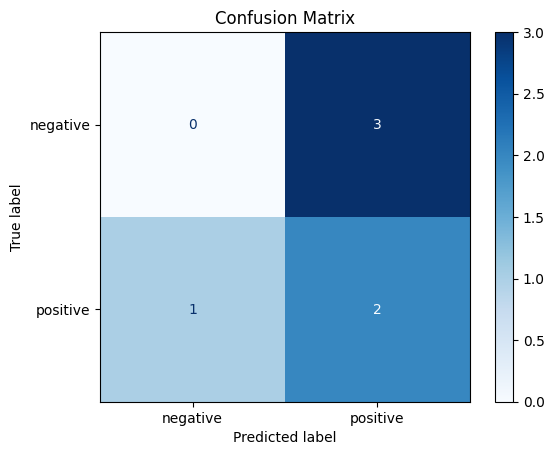

In [9]:
# [빈칸 11] 테스트 데이터에 대한 예측 메서드
y_pred = model.predict(X_test)
# [빈칸 12] 정답과 예측값의 정확도 계산 함수
acc = accuracy_score(y_test, y_pred)
print(f'테스트 정확도: {acc:.3f}')
print(classification_report(y_test, y_pred, labels=[0,1], target_names=['negative','positive'], zero_division=0))
cm = confusion_matrix(y_test, y_pred, labels=[0,1])
ConfusionMatrixDisplay(cm, display_labels=['negative','positive']).plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

## Part 4. 결과 해석 (서술형)
아래 질문에 **각 2~4문장**으로 답하세요.

1. BoW와 TF-IDF는 같은 문서를 어떤 기준으로 다르게 표현하나요?

**답:** BoW는 문서에 등장하는 단어의 빈도를 기준으로 표현한다. TF-IDF는 단어의 빈도뿐 아니라 전체 문서에서 해당 단어가 얼마나 드물게 등장하는지도 반영하여 가중치를 부여한다.

2. 문서 1과 문서 2의 코사인 유사도는 왜 0이 아니며, 유사도가 높다는 것이 반드시 같은 의미를 뜻하지 않는 이유는 무엇인가요?

**답:** 두 문서에 공통으로 등장하는 단어인 ‘귀엽다’가 있어 코사인 유사도가 0.316으로 나타났다. 단어의 순서나 문맥을 충분히 반영하지 못하므로 유사도가 높아도 의미가 같다고 볼 수는 없다.

3. 테스트 정확도를 기록하고, 표본 수가 20개뿐인 현재 결과를 실제 서비스 성능으로 일반화하기 어려운 이유를 설명하세요.

**답:** 테스트 정확도는 0.333(33.3%)으로, 테스트 데이터 6개 중 2개를 맞혔다. 전체 표본이 20개뿐이므로 다양한 표현을 충분히 학습하기 어렵고, 테스트 데이터 구성에 따라 정확도가 크게 달라질 수 있다. 따라서 실제 서비스 성능으로 일반화하기 어렵다.

4. 한국어에서 공백 기준 토큰화의 한계를 예시와 함께 설명하세요.

**답:** 한국어는 조사와 어미가 단어에 붙기 때문에 공백 기준으로 분리하면 같은 의미의 단어도 서로 다른 토큰으로 처리될 수 있다. 예를 들어 ‘배송이’와 ‘배송은’은 같은 명사 ‘배송’을 포함하지만 서로 다른 토큰으로 인식된다.

5. (선택) 같은 리뷰에서 부정어 **“안”**을 제거하면 감정 분류에 어떤 문제가 생길 수 있나요?

**답:** ‘안 좋아요’에서 ‘안’을 제거하면 ‘좋아요’만 남아 부정적인 표현이 긍정적인 표현으로 바뀔 수 있다. 이로 인해 모델이 부정 리뷰를 긍정으로 잘못 분류할 수 있다.


### 제출 전 확인
- [x] 빈칸 12개를 모두 채웠다.
- [x] 모든 셀을 처음부터 순서대로 실행했다.
- [x] BoW/TF-IDF 표, 유사도 행렬, 혼동행렬이 출력된다.
- [x] 서술형 답변을 작성했다.

**참고:** scikit-learn 공식 문서의 CountVectorizer, TfidfVectorizer, Pipeline, LogisticRegression, cosine_similarity.